# UTS Graf Sains Data: Neo4j + Rekomendasi (RetailRocket)

**Nama:** Ayu Ghaniyatur Rohmah

**NIM:** 23031554178

| Fold | Awal | Akhir |
|---|---|---|
| Training (P1) | 22 Mei 2015 | 10 Agustus 2015 |
| Testing (P2) | 11 Agustus 2015 | 31 Agustus 2015 |

**Ringkasan** 

Data interaksi RetailRocket (`events.csv`, 2.756.101 baris, 3 Mei sampai 18 September 2015) dimodelkan sebagai graf bipartit Visitor-Item di Neo4j (instance *UTS Graf*, versi 2026.09.0) dan diakses lewat driver Python. Graf dibentuk dari fold training (P1), lalu dipakai untuk menghitung similarity item-item dan membangun rekomendasi KNN yang dievaluasi pada fold testing (P2).

## Persiapan

In [ ]:
import os, getpass
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import normalize
from tqdm import tqdm
from neo4j import GraphDatabase

SEED = 42                               # seed tetap -> semua proses acak dapat direproduksi
DATA_DIR = "data"
URI = "neo4j://127.0.0.1:7687"          
DB = "neo4j"

P1 = ("2015-05-22", "2015-08-10")       
P2 = ("2015-08-11", "2015-08-31")       

W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}   # bobot interaksi (pilihan desain)
MIN_USERS = 3                            # item harus disentuh >= 3 user agar ikut dihitung similarity-nya

In [ ]:
# [NEO4J] koneksi. Password diminta lewat kotak input 
PASSWORD = os.environ.get("NEO4J_PW") or getpass.getpass("Password Neo4j: ")
driver = GraphDatabase.driver(URI, auth=("neo4j", PASSWORD))
driver.verify_connectivity()
print("Terhubung ke Neo4j")

def q(cypher, **params):
    """Jalankan Cypher via Python API, kembalikan DataFrame."""
    records, _, _ = driver.execute_query(cypher, parameters_=params, database_=DB)
    return pd.DataFrame([r.data() for r in records])

Terhubung ke Neo4j


## 2.1 Wrangling dan EDA

### No. 1. Menentukan 2 periode waktu
`timestamp` pada RetailRocket berupa unix epoch dalam **milidetik**, dibaca sebagai waktu **UTC**.

In [8]:
df = pd.read_csv(f"{DATA_DIR}/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")      # UTC
print("Jumlah baris :", len(df))
print("Rentang data :", df["dt"].min(), "->", df["dt"].max())
print(df["event"].value_counts())

Jumlah baris : 2756101
Rentang data : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


**Penjelasan:**

 Data asli mencakup 2.756.101 baris (3 Mei 2015 03:00 sampai 18 September 2015 02:59 UTC) dengan komposisi event: view 2.664.312, addtocart 69.332, dan transaction 22.457. Dua periode yang dipakai:

- **P1 (training), 22/05/2015 sampai 10/08/2015 (81 hari):** 1.682.577 baris (±61% dari seluruh data). Dipakai untuk membentuk graf dan menghitung similarity.
- **P2 (testing), 11/08/2015 sampai 31/08/2015 (21 hari):** 375.700 baris (±14%). Tidak dimasukkan ke graf; dipakai sebagai kunci jawaban evaluasi (Hit@5 dan NDCG@5).

Data di luar kedua periode tidak dipakai. P2 berada tepat sesudah P1 dan tidak beririsan (pemeriksaan `assert p1.dt.max() < p2.dt.min()` lolos (pada No.2)), sehingga model tidak melihat data masa depan. Skema ini meniru kondisi nyata: rekomendasi dibangun dari riwayat lalu, kemudian diuji pada perilaku yang terjadi sesudahnya. Batas tanggal dipakai inklusif (sampai 23:59:59) dan waktu dibaca dalam UTC.

### No. 2. Filter timestamp dan simpan ke CSV

In [ ]:
def cut(d, start, end):
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)            
    return d[(d["dt"] >= s) & (d["dt"] < e)]

p1 = cut(df, *P1)
p2 = cut(df, *P2)
assert p1["dt"].max() < p2["dt"].min(), "Periode tumpang tindih!"

p1.drop(columns="dt").to_csv(f"{DATA_DIR}/events_p1.csv", index=False)
p2.drop(columns="dt").to_csv(f"{DATA_DIR}/events_p2.csv", index=False)

ringkas = pd.DataFrame({
    "baris":       [len(p1), len(p2)],
    "visitor_unik":[p1["visitorid"].nunique(), p2["visitorid"].nunique()],
    "item_unik":   [p1["itemid"].nunique(), p2["itemid"].nunique()],
    "view":        [(p1["event"] == "view").sum(), (p2["event"] == "view").sum()],
    "addtocart":   [(p1["event"] == "addtocart").sum(), (p2["event"] == "addtocart").sum()],
    "transaction": [(p1["event"] == "transaction").sum(), (p2["event"] == "transaction").sum()],
    "mulai":       [p1["dt"].min(), p2["dt"].min()],
    "akhir":       [p1["dt"].max(), p2["dt"].max()],
}, index=["P1 (training)", "P2 (testing)"])
display(ringkas.T)

,P1 (training),P2 (testing)
baris,1682577,375700
visitor_unik,867962,213338
item_unik,190004,92555
view,1626898,362450
addtocart,41938,10004
transaction,13741,3246
mulai,2015-05-22 00:00:01.772000,2015-08-11 00:00:00.692000
akhir,2015-08-10 23:59:58.662000,2015-08-31 23:59:58.647000


**Hasil Filter (Output No. 2)**

| | P1 (training) | P2 (testing) |
|---|---|---|
| Baris | 1.682.577 | 375.700 |
| Visitor unik | 867.962 | 213.338 |
| Item unik | 190.004 | 92.555 |
| view | 1.626.898 | 362.450 |
| addtocart | 41.938 | 10.004 |
| transaction | 13.741 | 3.246 |
| Rentang waktu | 22/05/2015 00:00:01 s.d. 10/08/2015 23:59:58 | 11/08/2015 00:00:00 s.d. 31/08/2015 23:59:58 |

Hasil filter disimpan ke `data/events_p1.csv` dan `data/events_p2.csv`.


### Impor P1 ke Neo4j  **[TERMINAL]**
1. Di Neo4j Query, kosongkan database: `MATCH (n) DETACH DELETE n;`
2. Di terminal VS Code (`myvenv` aktif, folder proyek):

```
python import_retailrocket.py -p PASSWORD_ANDA -f events_p1.csv
```
Hanya **P1** yang diimpor ke graf. **P2** tetap di luar graf sebagai kunci jawaban pengujian (2.2).

### No. 3. Komposisi subgraph (jenis dan jumlah simpul)

In [ ]:
# [NEO4J]
jumlah_simpul = q("""
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC""")
display(jumlah_simpul)

jumlah_relasi = q("""
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC""")
display(jumlah_relasi)

# Pembuktian
print("Dari CSV P1 ->", p1["event"].value_counts().to_dict(),
      "| visitor unik:", p1["visitorid"].nunique(), "| item unik:", p1["itemid"].nunique())

,jenis_simpul,jumlah
0,Visitor,867962
1,Item,190004


,jenis_relasi,jumlah
0,VIEWED,1626898
1,ADDED_TO_CART,41938
2,BOUGHT,13741


Dari CSV P1 -> {'view': 1626898, 'addtocart': 41938, 'transaction': 13741} | visitor unik: 867962 | item unik: 190004


**Hasil (Output No. 3)**

Total 1.057.966 simpul dan Total 1.682.577 relasi. 

Semua angka sama persis dengan isi `events_p1.csv`, sehingga impor terbukti lengkap dan tidak ada data ganda.

**Penjelasan Cypher**
- `MATCH (n)` mengambil semua simpul; `labels(n)` mengembalikan daftar label tiap simpul; `UNWIND` memecah daftar itu menjadi satu baris per label.
- `count(*)` menghitung per `label` (kolom non-agregat otomatis menjadi kunci pengelompokan).
- `MATCH ()-[r]->()` mengambil semua relasi, `type(r)` menamai jenisnya.
- Saat impor, simpul dibuat dengan `MERGE` (satu visitor atau item hanya satu simpul walau muncul berkali-kali), sedangkan relasi dibuat dengan `CREATE` (satu baris data = satu relasi).
- Simpul: `Visitor` (pengunjung) dan `Item` (produk). Relasi: `VIEWED`, `ADDED_TO_CART`, `BOUGHT`.
- Graf ini **bipartit**: relasi hanya dari Visitor ke Item, tidak ada relasi Visitor-Visitor maupun Item-Item.

### No. 4 dan 5. Vector Space Modelling (VSM) untuk User dan Item
Interaksi diubah menjadi satu bilangan per pasangan (user, item) sebagai **bobot**:
view = 1, addtocart = 3, transaction = 5 (pembelian adalah sinyal minat terkuat).

Hasilnya matriks **X** (user x item):
- **VSM User** = baris-baris X: tiap user adalah vektor berdimensi sebanyak item.
- **VSM Item** = baris-baris X transpos: tiap item adalah vektor berdimensi sebanyak user.

In [4]:
# [NEO4J] ambil sisi graf yang sudah diagregasi per pasangan (user, item)
cy = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS w
"""
import gc
gc.collect()

buf_u, buf_i, buf_w = [], [], []
ch_u, ch_i, ch_w = [], [], []

def flush():
    if buf_u:
        ch_u.append(np.array(buf_u, dtype=np.int32))
        ch_i.append(np.array(buf_i, dtype=np.int32))
        ch_w.append(np.array(buf_w, dtype=np.int32))
        buf_u.clear(); buf_i.clear(); buf_w.clear()

with driver.session(database=DB) as s:
    for rec in s.run(cy):
        buf_u.append(rec["user"]); buf_i.append(rec["item"]); buf_w.append(rec["w"])
        if len(buf_u) >= 100_000:
            flush()
    flush()

edges = pd.DataFrame({"user": np.concatenate(ch_u), "item": np.concatenate(ch_i), "w": np.concatenate(ch_w)})
del ch_u, ch_i, ch_w
gc.collect()
print("Jumlah pasangan (user, item) unik:", f"{len(edges):,}", "| memori:", round(edges.memory_usage(deep=True).sum() / 1e6, 1), "MB")
edges.head()

Jumlah pasangan (user, item) unik: 1,310,421 | memori: 15.7 MB


,user,item,w
0,257597,355908,1
1,981382,355908,1
2,397425,355908,1
3,1080757,355908,1
4,601836,355908,1


In [5]:
u  = edges["user"].astype("category")
it = edges["item"].astype("category")
user_ids = u.cat.categories.to_numpy()
item_ids = it.cat.categories.to_numpy()

X = sp.csr_matrix(
    (edges["w"].to_numpy(dtype=np.float32), (u.cat.codes.to_numpy(), it.cat.codes.to_numpy())),
    shape=(len(user_ids), len(item_ids)),
)
XT = X.T.tocsr()

def describe(M, name):
    n, d = M.shape
    nnz = M.nnz
    mem_sparse = (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6
    mem_dense = n * d * 4 / 1e9
    print(f"{name}\n  shape={M.shape} | jumlah vektor={n:,} | dimensi={d:,}\n"
          f"  nnz={nnz:,} | density={nnz/(n*d):.2e} | sparsity={(1-nnz/(n*d))*100:.4f}%\n"
          f"  memori sparse={mem_sparse:.1f} MB | andai dense float32={mem_dense:,.1f} GB\n")

describe(X,  "VSM User (baris = user, kolom = item)")
describe(XT, "VSM Item (baris = item, kolom = user)")

deg_u = np.diff(X.indptr)     # jumlah item unik per user
deg_i = np.diff(XT.indptr)    # jumlah user unik per item
print("Distribusi jumlah item per user:\n", pd.Series(deg_u).describe(percentiles=[.5, .9, .99]).round(2))
print("\nDistribusi jumlah user per item:\n", pd.Series(deg_i).describe(percentiles=[.5, .9, .99]).round(2))

VSM User (baris = user, kolom = item)
  shape=(867962, 190004) | jumlah vektor=867,962 | dimensi=190,004
  nnz=1,310,421 | density=7.95e-06 | sparsity=99.9992%
  memori sparse=14.0 MB | andai dense float32=659.7 GB

VSM Item (baris = item, kolom = user)
  shape=(190004, 867962) | jumlah vektor=190,004 | dimensi=867,962
  nnz=1,310,421 | density=7.95e-06 | sparsity=99.9992%
  memori sparse=11.2 MB | andai dense float32=659.7 GB

Distribusi jumlah item per user:
 count    867962.00
mean          1.51
std           6.46
min           1.00
50%           1.00
90%           2.00
99%           8.00
max        2951.00
dtype: float64

Distribusi jumlah user per item:
 count    190004.00
mean          6.90
std          18.61
min           1.00
50%           2.00
90%          15.00
99%          75.00
max        1773.00
dtype: float64


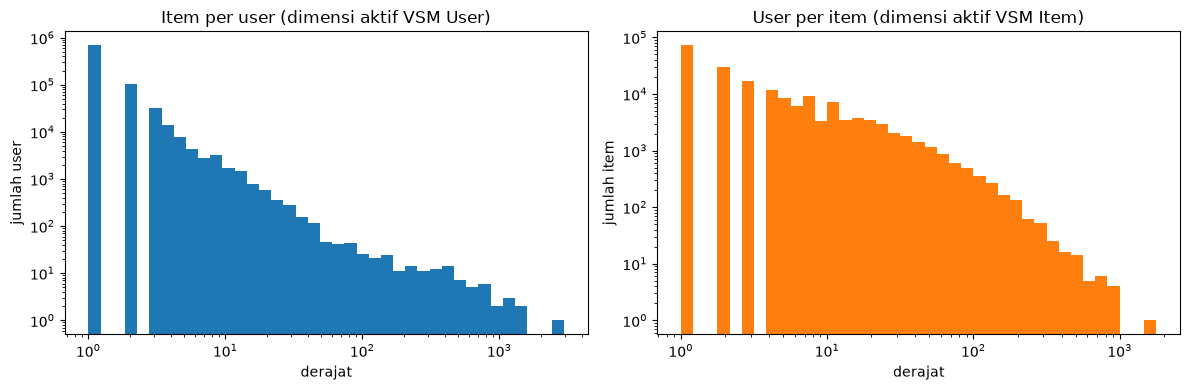

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(deg_u, bins=np.logspace(0, np.log10(deg_u.max() + 1), 40))
ax[0].set(xscale="log", yscale="log", title="Item per user (dimensi aktif VSM User)", xlabel="derajat", ylabel="jumlah user")
ax[1].hist(deg_i, bins=np.logspace(0, np.log10(deg_i.max() + 1), 40), color="tab:orange")
ax[1].set(xscale="log", yscale="log", title="User per item (dimensi aktif VSM Item)", xlabel="derajat", ylabel="jumlah item")
plt.tight_layout(); plt.show()

**Plot networkx** 

Graf penuh (1.057.966 simpul) terlalu besar untuk digambar, maka diambil **sampel yang bisa direproduksi** (seed 42): satu item "hub" dengan 8-25 user, beserta item lain milik user tersebut (user dengan lebih dari 10 item dibuang agar gambar terbaca). Sampel berisi 9 user, 13 item, dan 21 sisi. -

Panel kiri: graf bipartit; tengah: proyeksi ke User; kanan: proyeksi ke Item.

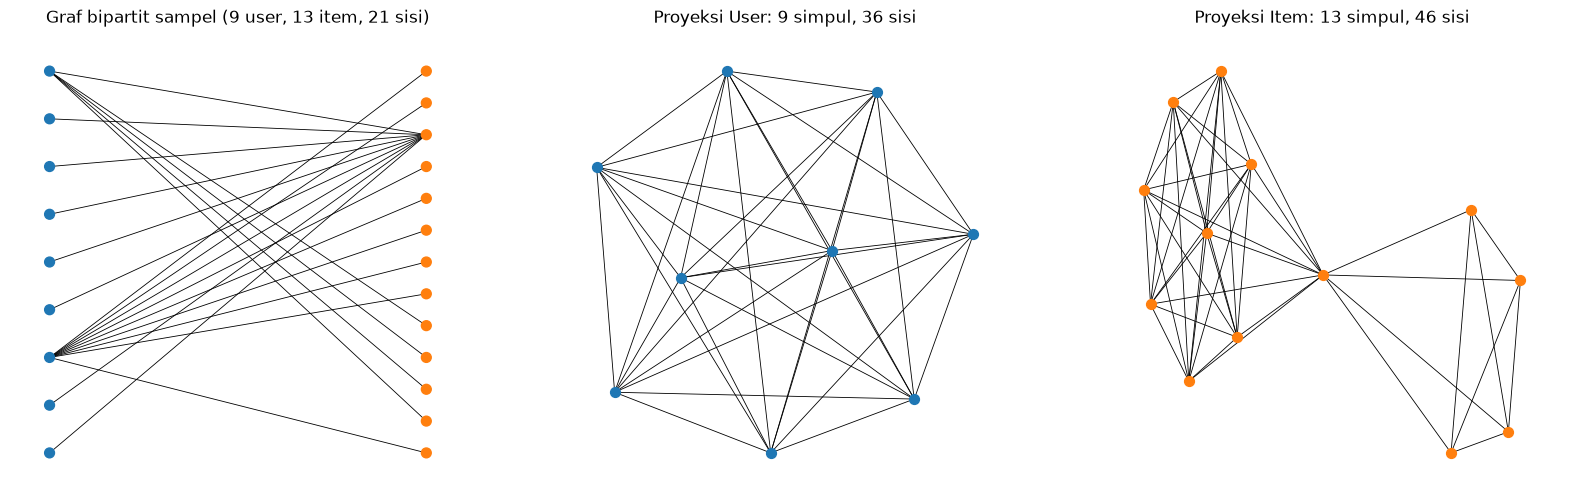

In [17]:
rng = np.random.default_rng(SEED)
cand = np.where((deg_i >= 8) & (deg_i <= 25))[0]            # posisi item dengan 8-25 user
if len(cand) == 0:
    cand = np.array([int(np.argmin(np.abs(deg_i - 15)))])
h = int(rng.choice(cand))                                    # posisi item "hub"
hub = int(item_ids[h])
us_pos = XT.indices[XT.indptr[h]:XT.indptr[h + 1]]           # user yang menyentuh hub
us_pos = us_pos[deg_u[us_pos] <= 10]                         # buang user yang terlalu aktif

rows_s = []
for up in us_pos:
    lo, hi = X.indptr[up], X.indptr[up + 1]
    for j, w in zip(X.indices[lo:hi], X.data[lo:hi]):
        rows_s.append((int(user_ids[up]), int(item_ids[j]), int(w)))
samp = pd.DataFrame(rows_s, columns=["user", "item", "w"])

U = [f"U{x}" for x in samp["user"].unique()]      # awalan U/I agar id user dan item tidak bertabrakan
I = [f"I{x}" for x in samp["item"].unique()]
B = nx.Graph()
B.add_nodes_from(U, bipartite=0)
B.add_nodes_from(I, bipartite=1)
B.add_weighted_edges_from([(f"U{a}", f"I{b}", w) for a, b, w in samp.itertuples(index=False)])

Pu = nx.bipartite.weighted_projected_graph(B, U)
Pi = nx.bipartite.weighted_projected_graph(B, I)
Uset = set(U)

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
nx.draw(B, nx.bipartite_layout(B, U), ax=ax[0], node_size=50, with_labels=False, width=0.6,
        node_color=["tab:blue" if n in Uset else "tab:orange" for n in B])
ax[0].set_title(f"Graf bipartit sampel ({len(U)} user, {len(I)} item, {B.number_of_edges()} sisi)")
nx.draw(Pu, nx.spring_layout(Pu, seed=SEED), ax=ax[1], node_size=50, node_color="tab:blue", width=0.6)
ax[1].set_title(f"Proyeksi User: {Pu.number_of_nodes()} simpul, {Pu.number_of_edges()} sisi")
nx.draw(Pi, nx.spring_layout(Pi, seed=SEED), ax=ax[2], node_size=50, node_color="tab:orange", width=0.6)
ax[2].set_title(f"Proyeksi Item: {Pi.number_of_nodes()} simpul, {Pi.number_of_edges()} sisi")
plt.show()

**Karakteristik VSM (dari output di atas)**

| Karakteristik | VSM User | VSM Item |
|---|---|---|
| Bentuk (shape) | 867.962 x 190.004 | 190.004 x 867.962 |
| Jumlah vektor | 867.962 user | 190.004 item |
| Dimensi | 190.004 (satu dimensi per item) | 867.962 (satu dimensi per user) |
| Entri tak-nol (nnz) | 1.310.421 | 1.310.421 |
| Density | 7,95 x 10^-6 | 7,95 x 10^-6 |
| Sparsity | 99,9992% | 99,9992% |
| Memori format sparse | 14,0 MB | 11,2 MB |
| Memori andai dense (float32) | 659,7 GB | 659,7 GB |
| Distribusi derajat | item per user: rata-rata 1,51; median 1; persentil 90 = 2; persentil 99 = 8; maks 2.951 | user per item: rata-rata 6,90; median 2; persentil 90 = 15; persentil 99 = 75; maks 1.773 |

- Kedua VSM adalah matriks yang sama (X dan transposnya): isinya sama, hanya sudut pandangnya berbeda. Pada VSM User, tiap user dicirikan oleh item yang disentuhnya, sedangkan pada VSM Item, tiap item dicirikan oleh user yang menyentuhnya.
- Matriks **sangat sparse**: hanya 0,0008% sel yang terisi. Bentuk dense membutuhkan 659,7 GB, sedangkan format sparse (CSR) hanya 11-14 MB, sehingga penyimpanan sparse wajib dipakai.
- nnz (1.310.421) lebih kecil daripada jumlah relasi di graf (1.682.577) karena pasangan (user, item) yang berulang digabung menjadi satu sel dengan bobot dijumlahkan (372.156 interaksi berulang).
- Distribusi derajat berbentuk *long tail* (histogram log-log): median user hanya menyentuh 1 item dan 90% user menyentuh paling banyak 2 item, tetapi ada user ekstrem dengan 2.951 item. **Item**: median hanya 2 user, 90% item disentuh paling banyak 15 user, tetapi ada item populer dengan 1.773 user. Akibatnya sebagian besar vektor user nyaris kosong dan sulit dibandingkan satu sama lain, sedangkan vektor item sedikit lebih kaya.
- Plot networkx: pada sampel (9 user, 13 item, 21 sisi), satu item populer disentuh oleh semua 9 user. Karena itu **Proyeksi User** berbentuk graf lengkap (9 simpul, 36 sisi = 9x8/2): setiap pasang user terhubung karena sama-sama menyentuh item tersebut. **Proyeksi Item** berisi 13 simpul dan 46 sisi (dari maksimum 78), membentuk dua kelompok yang dihubungkan oleh satu item. Ini menunjukkan bahwa item populer "menghubungkan" semua penggunanya sehingga proyeksi menjadi jauh lebih padat daripada graf bipartit asalnya (21 sisi menjadi 36 dan 46 sisi).

### No. 6. Proyeksi mana yang lebih baik (efektif dan efisien)?
Ukuran yang dipakai: ukuran matriks similarity penuh (n x n), dan estimasi jumlah pasangan yang benar-benar
punya kesamaan (dua simpul berbagi minimal satu tetangga).

In [6]:
n_users, n_items = X.shape
du = deg_u.astype(np.float64)
di = deg_i.astype(np.float64)

pairs_user_proj = float((di * (di - 1) / 2).sum())   # tiap item mempertemukan semua pasangan usernya
pairs_item_proj = float((du * (du - 1) / 2).sum())   # tiap user mempertemukan semua pasangan itemnya

banding = pd.DataFrame({
    "jumlah simpul":                         [n_users, n_items],
    "matriks similarity penuh (n x n)":      [float(n_users) ** 2, float(n_items) ** 2],
    "memori dense float32 (GB)":             [float(n_users) ** 2 * 4 / 1e9, float(n_items) ** 2 * 4 / 1e9],
    "pasangan ko-interaksi (batas atas)":    [pairs_user_proj, pairs_item_proj],
    "median interaksi per simpul":           [np.median(deg_u), np.median(deg_i)],
}, index=["Proyeksi User", "Proyeksi Item"])
display(banding.apply(lambda c: c.map("{:,.2f}".format)))

pilih = "Item" if n_items < n_users else "User"
print("Rasio jumlah user : item =", round(n_users / n_items, 2))
print("Proyeksi yang lebih efisien menurut ukuran matriks:", pilih)

,jumlah simpul,matriks similarity penuh (n x n),memori dense float32 (GB),pasangan ko-interaksi (batas atas),median interaksi per simpul
Proyeksi User,"867,962.00","753,358,033,444.00","3,013.43","36,772,209.00",1.00
Proyeksi Item,"190,004.00","36,101,520,016.00",144.41,"18,438,645.00",2.00


Rasio jumlah user : item = 4.57
Proyeksi yang lebih efisien menurut ukuran matriks: Item


**Hasil perbandingan (output di atas)**

| Ukuran | Proyeksi User | Proyeksi Item |
|---|---|---|
| Jumlah simpul | 867.962 | 190.004 |
| Matriks similarity penuh (n x n) | ±7,53 x 10^11 sel | ±3,61 x 10^10 sel |
| Memori dense float32 | 3.013,4 GB | 144,4 GB |
| Pasangan ko-interaksi (batas atas) | 36.772.209 | 18.438.645 |
| Median interaksi per simpul | 1 | 2 |

**Kesimpulan: Proyeksi Item lebih baik (efisien dan efektif).**
1. **Efisiensi:** User 4,57 kali lebih banyak daripada item, sehingga matriks similarity user ±20,9 kali lebih besar (7,53 x 10^11 dibanding 3,61 x 10^10 sel), dan jumlah pasangan yang berbagi tetangga ±2 kali lebih banyak (36,8 juta dibanding 18,4 juta). Matriks penuh keduanya tidak realistis disimpan dense (3.013 GB dan 144 GB), tetapi proyeksi Item jauh lebih mudah dihitung bertahap dan cukup menyimpan top-k tetangga per item.
2. **Efektivitas:** Vektor item punya bukti lebih banyak (median 2 user, persentil 90 = 15 user) dibanding vektor user (median 1 item, persentil 90 = 2 item). Kebanyakan user hanya menyentuh 1-2 item sehingga kesamaan antar-user sulit diandalkan, sedangkan kesamaan item dihitung dari perilaku banyak user.
3. **Kepraktisan:** Similarity item dapat dihitung di depan (offline) dan dipakai ulang untuk user baru mana pun yang punya riwayat, sedangkan di proyeksi User setiap user baru (jumlahnya sangat besar) memerlukan perhitungan baru.

Catatan: selisih jumlah pasangan hanya ±2 kali, jauh lebih kecil daripada selisih ukuran matriks, karena sebagian pasangan item berasal dari sedikit user ekstrem (satu user dengan 2.951 item saja menghasilkan ±4,35 juta pasangan item, atau ±24% dari batas atas 18,4 juta). Karena itu pada No. 7 hanya item yang disentuh minimal 3 user yang dihitung dan tiap item hanya menyimpan 5 tetangga terdekat. Bagian berikutnya memakai proyeksi Item.

### No. 7. Similarity pada graf yang diproyeksikan (Item-Item)
Metode: **cosine similarity** pada vektor biner (item disentuh atau tidak oleh user):

cosine(A, B) = |user(A) ∩ user(B)| / sqrt(|user(A)| x |user(B)|)

Rumus ini sengaja dibuat sederhana supaya hasil Python bisa dibuktikan langsung dengan Cypher.
Untuk tiap item disimpan **k = 5 tetangga terdekat**. Hanya item yang disentuh minimal `MIN_USERS` user
yang dihitung (item dengan 1-2 user terlalu sedikit bukti dan membuat komputasi berat).

In [8]:
def topk_cosine(M, k=5, chunk=100):
    """M: matriks (item x user). Kembalikan list (baris_a, baris_b, cosine) top-k per baris.
    Hemat memori: hasil perkalian disimpan sparse (hanya pasangan yang berbagi minimal 1 user)."""
    Mn = normalize(M).tocsr().astype(np.float32)
    MT = Mn.T.tocsr()                                       # dibuat sekali (csr) agar perkalian tidak menyalin ulang
    out = []
    for s in tqdm(range(0, Mn.shape[0], chunk), desc="Hitung similarity"):
        P = (Mn[s:s + chunk] @ MT).tocsr()                  # sparse: chunk x item
        for a in range(P.shape[0]):
            lo, hi = P.indptr[a], P.indptr[a + 1]
            cols, vals = P.indices[lo:hi], P.data[lo:hi]
            m = cols != (s + a)                             # buang diri sendiri
            cols, vals = cols[m], vals[m]
            if len(vals) > k:
                top = np.argpartition(-vals, k - 1)[:k]
                cols, vals = cols[top], vals[top]
            out.extend((s + a, int(c), float(v)) for c, v in zip(cols, vals))
        del P
    return out

Xb = XT.copy()
Xb.data[:] = 1                                              # biner
keep = np.where(deg_i >= MIN_USERS)[0]
kept_items = item_ids[keep]
print(f"Item dihitung: {len(keep):,} dari {n_items:,} (ambang >= {MIN_USERS} user)")

pairs = topk_cosine(Xb[keep], k=5)
sim = pd.DataFrame({
    "a":     kept_items[[p[0] for p in pairs]],
    "b":     kept_items[[p[1] for p in pairs]],
    "score": [p[2] for p in pairs],
})
print("Jumlah pasangan similarity:", len(sim))
sim.head(10)

Item dihitung: 86,390 dari 190,004 (ambang >= 3 user)


Hitung similarity: 100%|██████████| 864/864 [00:07<00:00, 114.11it/s]


Jumlah pasangan similarity: 293134


,a,b,score
0,6,440450,0.123091
1,6,99298,0.123091
2,6,56944,0.123091
3,6,432868,0.106600
4,6,26514,0.106600
5,15,34219,0.248069
6,15,75670,0.160128
7,15,10187,0.160128
8,15,78102,0.160128
9,15,212804,0.160128


**Hasil perhitungan similarity:** 

Dari 190.004 item, 86.390 item (45,5%) memenuhi ambang minimal 3 user dan dihitung (864 potongan, ±7 detik). Hasilnya 293.134 pasangan (a, b, score), lebih sedikit daripada 5 x 86.390 = 431.950 karena sebagian item punya kurang dari 5 tetangga yang berbagi user. Item dengan skor sama (misalnya tiga tetangga item 6 sama-sama 0,123091) boleh berbeda urutannya.

**(a)** Item acuan dipilih acak (seed 42) dari item dengan 20-100 user: **itemId 44220** (disentuh 79 user). Top-5 item termiripnya dihitung di Python dan dibuktikan dengan Cypher.

In [9]:
deg_item_map = dict(zip(item_ids.tolist(), deg_i.tolist()))
pool = sorted(int(a) for a in sim["a"].unique() if 20 <= deg_item_map[int(a)] <= 100) \
       or sorted(int(a) for a in sim["a"].unique())
ref = int(np.random.default_rng(SEED).choice(pool))
print("Item acuan:", ref, "| jumlah user yang menyentuhnya:", deg_item_map[ref])

top5_py = sim[sim["a"] == ref].sort_values("score", ascending=False).head(5).reset_index(drop=True)
display(top5_py)

Item acuan: 44220 | jumlah user yang menyentuhnya: 79


,a,b,score
0,44220,125440,0.137338
1,44220,381934,0.115771
2,44220,129326,0.112509
3,44220,340949,0.100631
4,44220,138230,0.087855


In [10]:
# [NEO4J] Cosine yang sama dihitung langsung dari graf
cy_top5 = """
MATCH (a:Item {itemId: $ref})<--(ua:Visitor)
WITH a, collect(DISTINCT ua) AS ua_list, count(DISTINCT ua) AS na
UNWIND ua_list AS u
MATCH (u)-->(b:Item) WHERE b <> a
WITH a, na, b, count(DISTINCT u) AS common
MATCH (b)<--(ub:Visitor)
WITH a, na, b, common, count(DISTINCT ub) AS nb
WHERE nb >= $min_users
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, common, na, nb,
       common / sqrt(toFloat(na) * nb) AS cosine
ORDER BY cosine DESC, item_mirip
LIMIT 5
"""
top5_cy = q(cy_top5, ref=ref, min_users=MIN_USERS)
display(top5_cy)
print("Skor Python :", top5_py["score"].round(4).tolist())
print("Skor Cypher :", top5_cy["cosine"].round(4).tolist())

,item_acuan,item_mirip,common,na,nb,cosine
0,44220,125440,15,79,151,0.137338
1,44220,381934,6,79,34,0.115771
2,44220,129326,2,79,4,0.112509
3,44220,340949,2,79,5,0.100631
4,44220,138230,5,79,41,0.087855


Skor Python : [0.1373, 0.1158, 0.1125, 0.1006, 0.0879]
Skor Cypher : [0.1373, 0.1158, 0.1125, 0.1006, 0.0879]


**Hasil pembuktian:** 

Top-5 dari Python dan dari Cypher identik (skor 0,1373; 0,1158; 0,1125; 0,1006; 0,0879), sehingga perhitungan Python valid.

| item_mirip | common | na | nb | cosine |
|---|---|---|---|---|
| 125440 | 15 | 79 | 151 | 0,1373 |
| 381934 | 6 | 79 | 34 | 0,1158 |
| 129326 | 2 | 79 | 4 | 0,1125 |
| 340949 | 2 | 79 | 5 | 0,1006 |
| 138230 | 5 | 79 | 41 | 0,0879 |

`common` = jumlah user yang menyentuh kedua item, `na` = jumlah user item acuan (79), `nb` = jumlah user item pembanding. Contoh: 15 / sqrt(79 x 151) = 0,1373.

Catatan: cosine biner cenderung menyukai item yang jarang disentuh. Item 129326 (hanya 4 user) dan 340949 (5 user) berada di peringkat 3-4 walau hanya berbagi 2 user dengan item acuan, sedangkan 138230 (5 user bersama, 41 user total) justru di peringkat 5. Pembagi sqrt(na x nb) memperkecil skor item populer. Ambang minimal 3 user hanya membuang kasus paling ekstrem (item dengan 1-2 user); bias ini tetap ada.

**(b)** Similarity ditulis ke graf sebagai relasi `SIMILAR_TO {score, method}` memakai `MERGE` (aman diulang, tidak membuat duplikat). Penulisan 293.134 relasi dalam 59 batch (5.000 per batch) memakan ±3 menit 20 detik. Query hasilnya menampilkan 5 relasi dari item 44220 dengan skor yang sama seperti pada (a).

Catatan: hitungan "sebelum penulisan" pada output menunjukkan 170.000 relasi karena sisa percobaan penulisan sebelumnya yang tidak selesai (170.000 = 34 batch x 5.000). Karena memakai `MERGE`, penulisan ulang tidak membuat duplikat dan hasil akhirnya (293.134) sama dengan jumlah pasangan pada `sim`. Kondisi graf **sebelum** perhitungan similarity yang sebenarnya terlihat pada output No. 3: hanya tiga tipe relasi interaksi dan tidak ada `SIMILAR_TO`.

In [11]:
# [NEO4J]
n_sim_sebelum = int(q("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n")["n"][0])
print("Relasi SIMILAR_TO SEBELUM penulisan:", n_sim_sebelum)

rows = [{"a": int(a), "b": int(b), "score": float(s)} for a, b, s in zip(sim["a"], sim["b"], sim["score"])]
cy_write = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score, s.method = 'cosine-binary'
"""
with driver.session(database=DB) as s:
    for i in tqdm(range(0, len(rows), 5000), desc="Menulis SIMILAR_TO"):
        s.run(cy_write, rows=rows[i:i + 5000]).consume()

n_sim_sesudah = int(q("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n")["n"][0])
print("Relasi SIMILAR_TO SESUDAH penulisan:", n_sim_sesudah)

display(q("""
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS score
ORDER BY score DESC LIMIT 5""", ref=ref))

Relasi SIMILAR_TO SEBELUM penulisan: 170000


Menulis SIMILAR_TO: 100%|██████████| 59/59 [03:20<00:00,  3.41s/it]


Relasi SIMILAR_TO SESUDAH penulisan: 293134


,acuan,mirip,score
0,44220,125440,0.137338
1,44220,381934,0.115771
2,44220,129326,0.112509
3,44220,340949,0.100631
4,44220,138230,0.087855


### No. 8. Kondisi graf sebelum dan sesudah perhitungan similarity

Item acuan: **44220**. Query dijalankan di menu **Query** Neo4j Desktop (tampilan Graph).

1. **Graf Sebelum Perhitungan Similarity:** hanya relasi interaksi (tidak ada relasi antar-item).
    ```cypher
    MATCH p = (a:Item {itemId: 44220})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
    RETURN p LIMIT 25
    ```
    ![Graf sebelum](images/no8_sebelum.png)
    
    Graf hanya memiliki tiga tipe relasi interaksi (VIEWED 1.626.898; ADDED_TO_CART 41.938; BOUGHT 13.741; total 1.682.577, sesuai output No. 3) dan tidak ada relasi antar-item. Item 44220 hanya berhubungan dengan item lain secara tidak langsung lewat visitor yang sama (Item - Visitor - Item), sehingga kemiripan harus dihitung dengan menelusuri banyak jalur.

2. **Graf Sesudah Perhitungan Similarity:** item acuan terhubung langsung ke 5 item termirip.
    ```cypher
    MATCH p = (a:Item {itemId: 44220})-[:SIMILAR_TO]->(b:Item)
    RETURN p
    ```
    ![Graf sebelum](images/no8_sesudah.png)
    
    Ditambahkan relasi `SIMILAR_TO {score}` antar item. Item 44220 kini terhubung langsung ke 5 item termirip: 125440 (0,1373), 381934 (0,1158), 129326 (0,1125), 340949 (0,1006), dan 138230 (0,0879).

3. **Bukti angka:** jumlah relasi per tipe.
    ```cypher
    MATCH ()-[r]->()
    RETURN type(r) AS relasi, count(r) AS jumlah
    ORDER BY jumlah DESC
    ```
    ![Jumlah relasi](images/no8_angka.png)
    
    Bertambah 293.134 relasi `SIMILAR_TO`, sehingga total menjadi 1.975.711 relasi dengan 4 tipe. Jumlah simpul tidak berubah (1.057.966) karena similarity disimpan sebagai relasi, bukan simpul baru.

**Manfaat:** Rekomendasi cukup menelusuri satu langkah relasi `SIMILAR_TO` (dipakai pada validasi Cypher di 2.2 No. 1) tanpa menghitung ulang similarity.

## 2.2 Analytics

### No. 1. Pemilihan user acak (reproducible) dan rekomendasi KNN

**Protokol evaluasi**
- User kandidat: ada di graf P1, punya >= 3 item, dan berinteraksi di P2.
- Kunci jawaban (*ground truth*) = item yang disentuh user di **P2** (semua jenis event), **dikurangi** item yang sudah disentuhnya di P1 (rekomendasi memang tidak boleh mengulang item lama), dan dibatasi pada item yang dikenal model (>= `MIN_USERS` user).
- Pengacakan: `np.random.default_rng(SEED).choice(daftar_kandidat_terurut)` dengan `SEED = 42`, sehingga hasilnya sama setiap dijalankan.

**Hasil pemilihan (Output).** 

Terdapat 4.316 user kandidat (>= 3 item di P1 dan muncul di P2); 3.164 di antaranya memenuhi protokol (punya minimal satu item kunci jawaban yang dikenal model). 

User terpilih: **visitorId 121523**, dengan 4 item di P1 dan 2 item kunci jawaban di P2.

In [13]:
p2e = pd.read_csv(f"{DATA_DIR}/events_p2.csv", usecols=["visitorid", "itemid"])
truth_all = p2e.groupby("visitorid")["itemid"].agg(set)
p2_users = set(int(x) for x in truth_all.index.tolist())

user_pos = {int(x): i for i, x in enumerate(user_ids)}
universe = set(int(x) for x in kept_items)

def user_history(uid):
    """Item (dan bobot) yang disentuh user di P1."""
    i = user_pos[uid]
    lo, hi = X.indptr[i], X.indptr[i + 1]
    return {int(item_ids[j]): float(w) for j, w in zip(X.indices[lo:hi], X.data[lo:hi])}

def truth_eval(uid):
    seen = set(user_history(uid))
    new_items = {int(x) for x in truth_all.get(uid, ())} - seen
    return new_items & universe

cand_users = [int(x) for x in user_ids[deg_u >= 3] if int(x) in p2_users]
eligible = sorted(uid for uid in cand_users if truth_eval(uid))
print(f"Kandidat (>=3 item di P1 & ada di P2): {len(cand_users):,} | memenuhi protokol: {len(eligible):,}")

target = int(np.random.default_rng(SEED).choice(eligible))
print("User terpilih (visitorId):", target)
print("Item di P1 :", len(user_history(target)), "| item kunci jawaban di P2:", len(truth_eval(target)))

Kandidat (>=3 item di P1 & ada di P2): 4,316 | memenuhi protokol: 3,164
User terpilih (visitorId): 121523
Item di P1 : 4 | item kunci jawaban di P2: 2


**(a) Skrip rekomendasi KNN (item-based, k = 5 tetangga per item).**

Cara kerja: untuk tiap item *i* yang pernah disentuh user (bobot *w*: view 1, addtocart 3, transaction 5), diambil 5 tetangga terdekat *i* dari hasil similarity No. 7. Skor kandidat *c* = jumlah dari *w(i)* x cosine(*i*, *c*) atas semua item *i* milik user yang punya *c* sebagai tetangga. Item yang sudah pernah disentuh user dibuang, lalu 5 skor tertinggi diambil sebagai rekomendasi.

In [14]:
# Tetangga terdekat (k=5) setiap item, dari hasil similarity no. 7
nbr = defaultdict(list)
for a, b, s in zip(sim["a"], sim["b"], sim["score"]):
    nbr[int(a)].append((int(b), float(s)))

def recommend_item_knn(uid, topn=5):
    """Skor kandidat c = jumlah dari (bobot interaksi user pada item i) x cosine(i, c), untuk semua item i milik user
    yang punya c sebagai salah satu 5 tetangga terdekatnya. Item yang sudah pernah disentuh user dibuang."""
    hist = user_history(uid)
    scores = defaultdict(float)
    for item, w in hist.items():
        for nb, s in nbr.get(item, []):
            if nb not in hist:
                scores[nb] += w * s
    return sorted(scores.items(), key=lambda t: (-t[1], t[0]))[:topn]

rec = recommend_item_knn(target, topn=5)
rec_df = pd.DataFrame(rec, columns=["itemId", "skor"])
rec_df.index = rec_df.index + 1
rec_df.index.name = "peringkat"
display(rec_df)

,itemId,skor
peringkat,,
1,219897,0.473607
2,339083,0.338062
3,133980,0.250000
4,279359,0.223607
5,79473,0.184900


**(b) Tiga item yang diiklankan** (3 teratas dari daftar rekomendasi KNN k = 5) untuk visitor 121523:

| Peringkat | itemId | Skor |
|---|---|---|
| 1 | 219897 | 0,4736 |
| 2 | 339083 | 0,3381 |
| 3 | 133980 | 0,2500 |

Dua item berikutnya pada top-5: 279359 (0,2236) dan 79473 (0,1849). Query Cypher pembuktian (memakai relasi `SIMILAR_TO` di graf) menghasilkan lima item dan skor yang identik, sehingga skrip Python valid.

In [15]:
iklan = rec_df.head(3)
print("Item yang diiklankan kepada visitor", target)
display(iklan)

Item yang diiklankan kepada visitor 121523


,itemId,skor
peringkat,,
1,219897,0.473607
2,339083,0.338062
3,133980,0.250000


In [16]:
# [NEO4J] Pembuktian: rekomendasi yang sama dihitung langsung dari graf (memakai relasi SIMILAR_TO)
cy_rec = """
MATCH (u:Visitor {visitorId: $u})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH u, i, sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS w
MATCH (i)-[s:SIMILAR_TO]->(c:Item)
WHERE NOT (u)-->(c)
RETURN c.itemId AS item, sum(w * s.score) AS skor
ORDER BY skor DESC, item
LIMIT 5
"""
display(q(cy_rec, u=target))

,item,skor
0,219897,0.473607
1,339083,0.338062
2,133980,0.250000
3,279359,0.223607
4,79473,0.184900


### No. 2. Evaluasi: Hit@5 dan NDCG@5
- **Hit@5** = 1 jika minimal satu dari 5 item teratas ada di kunci jawaban, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan DCG = jumlah dari rel / log2(peringkat + 1) untuk peringkat 1..5,
  rel = 1 bila item ada di kunci jawaban, dan IDCG = DCG pada urutan ideal.

In [17]:
def hit_at_k(ranked, rel, k=5):
    return int(any(i in rel for i in ranked[:k]))

def ndcg_at_k(ranked, rel, k=5):
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(ranked[:k]) if i in rel)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

truth = truth_eval(target)
ranked = [i for i, _ in rec]

detail = pd.DataFrame({
    "peringkat": range(1, len(ranked) + 1),
    "itemId": ranked,
    "relevan (rel)": [int(i in truth) for i in ranked],
    "gain = rel/log2(r+1)": [round(int(i in truth) / np.log2(r + 2), 4) for r, i in enumerate(ranked)],
})
display(detail)
print("Kunci jawaban (item P2):", sorted(truth))
print(f"Hit@5  = {hit_at_k(ranked, truth)}")
print(f"NDCG@5 = {ndcg_at_k(ranked, truth):.4f}")

,peringkat,itemId,relevan (rel),gain = rel/log2(r+1)
0,1,219897,0,0.0
1,2,339083,0,0.0
2,3,133980,0,0.0
3,4,279359,0,0.0
4,5,79473,0,0.0


Kunci jawaban (item P2): [68326, 175355]
Hit@5  = 0
NDCG@5 = 0.0000


**Hasil dan interpretasi**
- **User 121523.** Kunci jawaban di P2 = {68326, 175355}; top-5 rekomendasi (219897, 339083, 133980, 279359, 79473) tidak memuat satupun, sehingga **Hit@5 = 0** dan **NDCG@5 = 0,0000**. Satu user hanyalah satu sampel, jadi hasil ini tidak mewakili kinerja model.
- **Rata-rata 200 user acak** (seed 43): **Hit@5 = 0,0300** (sekitar 6 dari 200 user mendapat minimal satu item benar di 5 teratas) dan **NDCG@5 = 0,0183**. NDCG yang lebih kecil daripada Hit menunjukkan bahwa item yang benar umumnya tidak berada di peringkat teratas. Dengan 200 user, galat baku Hit@5 sekitar 0,012, jadi angka ini bersifat kasar.

**Mengapa nilainya rendah?**
1. Ruang kandidat sangat besar (86.390 item) sedangkan kunci jawaban hanya beberapa item per user. Peluang acak untuk mengenai satu item kunci jawaban dalam 5 tebakan hanya sekitar 5/86.390 = 0,006%, sehingga 3% sudah ratusan kali lipat di atas tebakan acak.
2. Riwayat user sangat pendek (user terpilih hanya 4 item; 90% user di P1 hanya menyentuh maksimal 2 item), sehingga sedikit item yang bisa menghasilkan tetangga.
3. Kunci jawaban hanya item baru bagi user (item lama dikeluarkan), padahal pada e-commerce banyak interaksi berupa kunjungan ulang.
4. Cosine biner cenderung menyukai item langka (lihat catatan No. 7), dan model tidak memakai informasi lain seperti popularitas atau kategori.

In [18]:
# Pelengkap: rata-rata pada 200 user acak (seed tetap)
rng2 = np.random.default_rng(SEED + 1)
sample_users = rng2.choice(eligible, size=min(200, len(eligible)), replace=False)

hits, ndcgs = [], []
for uid in sample_users:
    uid = int(uid)
    rk = [i for i, _ in recommend_item_knn(uid, topn=5)]
    rel = truth_eval(uid)
    hits.append(hit_at_k(rk, rel))
    ndcgs.append(ndcg_at_k(rk, rel))

print(f"Jumlah user dievaluasi : {len(sample_users)}")
print(f"Rata-rata Hit@5        : {np.mean(hits):.4f}")
print(f"Rata-rata NDCG@5       : {np.mean(ndcgs):.4f}")

Jumlah user dievaluasi : 200
Rata-rata Hit@5        : 0.0300
Rata-rata NDCG@5       : 0.0183


## Ringkasan Jawaban: 
### Tugas Pendahuluan (Pertanyaan Checkpoint)

1. **Database yang dipakai:** `neo4j`, yaitu database default (parameter `database_="neo4j"`).
2. **Akses database lain dalam satu instance:** lewat driver dengan `database_="nama_db"` pada `execute_query` atau `driver.session(database="nama_db")`; lewat Cypher dengan `USE nama_db MATCH ...`; DDL administrasi (`CREATE DATABASE`, `SHOW DATABASES`) dijalankan dari database `system`. Edisi Community hanya mengizinkan satu database pengguna.
3. **Jenis graf pertemanan:** graf **berarah** (`-[:KNOWS]->`), **homogen** (hanya label `Person` dan tipe relasi `KNOWS`), tanpa bobot, dan berbentuk **bintang** (Arthur sebagai pusat dengan 3 relasi keluar ke Guinevere, Lancelot, Merlin).

---

### 2.1 Wrangling dan EDA

### No. 1. Dua periode waktu
- **P1 (training):** 22/05/2015 s.d. 10/08/2015 (81 hari), **P2 (testing):** 11/08/2015 s.d. 31/08/2015 (21 hari).
- P2 tepat sesudah P1 dan tidak beririsan, sehingga tidak ada kebocoran data masa depan ke model.

### No. 2. Filter timestamp dan simpan CSV
`timestamp` (milidetik, UTC) diubah menjadi tanggal lalu difilter per periode (batas akhir inklusif sampai 23:59:59). Hasil disimpan ke `events_p1.csv` dan `events_p2.csv`.

| | P1 | P2 |
|---|---|---|
| Baris | 1.682.577 | 375.700 |
| Visitor unik | 867.962 | 213.338 |
| Item unik | 190.004 | 92.555 |

### No. 3. Komposisi subgraph
- **Simpul:** Visitor = 867.962; Item = 190.004 (total 1.057.966).
- **Relasi:** VIEWED = 1.626.898; ADDED_TO_CART = 41.938; BOUGHT = 13.741 (total 1.682.577). Semua sama persis dengan CSV P1.
- **Cypher:** `MATCH (n) UNWIND labels(n) AS label RETURN label, count(*)` menghitung simpul per label; `MATCH ()-[r]->() RETURN type(r), count(*)` menghitung relasi per tipe.
- Grafnya **bipartit**: relasi hanya dari Visitor ke Item.

### No. 4. VSM User
Matriks user x item (bobot: view 1, addtocart 3, transaction 5). Tiap user adalah vektor berdimensi 190.004 (satu dimensi per item).
- **Shape:** 867.962 x 190.004; **nnz:** 1.310.421; **sparsity:** 99,9992%.
- Memori sparse 14,0 MB (andai dense: 659,7 GB).
- Median user hanya menyentuh 1 item (persentil 90 = 2; maks 2.951), jadi vektornya hampir kosong.
- Plot networkx (9 user, 13 item): proyeksi User berbentuk graf lengkap (9 simpul, 36 sisi) karena semua user menyentuh satu item populer.

### No. 5. VSM Item
Transpos matriks yang sama. Tiap item adalah vektor berdimensi 867.962 (satu dimensi per user).
- **Shape:** 190.004 x 867.962; nnz dan sparsity sama dengan VSM User; memori sparse 11,2 MB.
- Median item disentuh 2 user (persentil 90 = 15; maks 1.773), sehingga vektornya lebih kaya daripada vektor user.
- Plot networkx: proyeksi Item 13 simpul dan 46 sisi, membentuk dua kelompok yang dihubungkan satu item.

### No. 6. Proyeksi yang lebih baik: **Item**
- Jumlah user 4,57 kali jumlah item, sehingga matriks similarity user ±20,9 kali lebih besar (7,53 x 10^11 vs 3,61 x 10^10 sel; dense 3.013 GB vs 144 GB).
- Pasangan yang berbagi tetangga: 36,8 juta (user) vs 18,4 juta (item).
- Vektor item punya bukti lebih banyak (median 2 vs 1), dan similarity item dapat dihitung di depan lalu dipakai ulang untuk user baru.

### No. 7. Similarity pada graf terproyeksi (Item-Item)
**Metode:** cosine biner, `cos(A,B) = |user(A) ∩ user(B)| / sqrt(|user(A)| x |user(B)|)`. Ambang minimal 3 user (86.390 dari 190.004 item), k = 5 tetangga terdekat per item, hasil 293.134 pasangan.

**(a)** Item acuan **44220** (79 user). Top-5 dihitung di Python dan Cypher dengan hasil identik:

| item_mirip | common | nb | cosine |
|---|---|---|---|
| 125440 | 15 | 151 | 0,1373 |
| 381934 | 6 | 34 | 0,1158 |
| 129326 | 2 | 4 | 0,1125 |
| 340949 | 2 | 5 | 0,1006 |
| 138230 | 5 | 41 | 0,0879 |

Cypher-nya menghitung `common` (user yang menyentuh kedua item), `na`, dan `nb`, lalu `common / sqrt(na x nb)`.

**(b)** Similarity ditulis ke graf sebagai relasi `(:Item)-[:SIMILAR_TO {score}]->(:Item)` memakai `MERGE` (293.134 relasi). Query `MATCH (a:Item {itemId: 44220})-[s:SIMILAR_TO]->(b) RETURN ...` menampilkan 5 relasi dengan skor yang sama seperti pada (a).

### No. 8. Graf sebelum dan sesudah similarity
```cypher
// Sebelum: hanya relasi interaksi
MATCH p = (a:Item {itemId: 44220})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
RETURN p LIMIT 25

// Sesudah: terhubung langsung lewat SIMILAR_TO
MATCH p = (a:Item {itemId: 44220})-[:SIMILAR_TO]->(b:Item)
RETURN p
```
- **Sebelum:** 3 tipe relasi (1.682.577 relasi); dua item hanya terhubung tidak langsung lewat visitor yang sama.
- **Sesudah:** bertambah 293.134 relasi `SIMILAR_TO` (total 1.975.711); item 44220 terhubung langsung ke 5 item termirip beserta skornya.

---

### 2.2 Analytics

### No. 1. User acak dan rekomendasi KNN
- **Pemilihan user:** kandidat = user dengan >= 3 item di P1 yang muncul di P2 dan punya item kunci jawaban baru (3.164 user). Dipilih dengan `np.random.default_rng(42).choice(...)` dari daftar terurut, sehingga reproducible. Hasil: **visitorId 121523** (4 item di P1; kunci jawaban P2 = {68326, 175355}).
- **(a) Skrip KNN (item-based, k = 5):** untuk tiap item milik user (bobot w), ambil 5 tetangga terdekatnya; skor kandidat = jumlah `w x cosine`; item yang sudah pernah disentuh dibuang; urutkan menurun.
- **(b) Tiga item yang diiklankan:**

| Peringkat | itemId | Skor |
|---|---|---|
| 1 | 219897 | 0,4736 |
| 2 | 339083 | 0,3381 |
| 3 | 133980 | 0,2500 |

(Top-5 lengkap: 219897, 339083, 133980, 279359, 79473. Validasi Cypher memberi hasil identik.)

### No. 2. Evaluasi
- **Hit@5** = 1 jika minimal satu dari 5 rekomendasi ada di kunci jawaban, selain itu 0.
- **NDCG@5** = DCG / IDCG, dengan DCG = jumlah dari rel / log2(peringkat + 1).

| | Hit@5 | NDCG@5 |
|---|---|---|
| User 121523 | 0 | 0,0000 |
| Rata-rata 200 user acak | 0,0300 | 0,0183 |

Nilainya rendah karena ruang kandidat besar (86.390 item), riwayat user pendek, dan data sangat sparse. Meski begitu, 3% jauh di atas tebakan acak (±0,006% per item kunci jawaban).

## Kesimpulan
1. **Periode:** P1 (22/05/2015 sampai 10/08/2015; 1.682.577 baris) dipakai untuk membentuk graf, P2 (11/08/2015 sampai 31/08/2015; 375.700 baris) sebagai data uji tanpa tumpang tindih.
2. **Komposisi graf:** 1.057.966 simpul (867.962 Visitor dan 190.004 Item) dan 1.682.577 relasi (VIEWED 1.626.898; ADDED_TO_CART 41.938; BOUGHT 13.741), sama persis dengan isi CSV P1. Grafnya bipartit.
3. **VSM:** Matriks user x item berukuran 867.962 x 190.004 dengan 1.310.421 entri tak-nol (sparsity 99,9992%), distribusi derajat *long tail*.
4. **Proyeksi:** Proyeksi Item dipilih karena matriks similarity-nya ±20,9 kali lebih kecil, buktinya lebih kaya per vektor, dan dapat dipakai ulang untuk user baru.
5. **Similarity:** Cosine biner item-item (k = 5, item dengan >= 3 user): 86.390 item dan 293.134 pasangan, dibuktikan identik antara Python dan Cypher (item acuan 44220), lalu ditulis ke graf sebagai relasi `SIMILAR_TO`.
6. **Rekomendasi:** KNN item-based (k = 5) untuk visitor 121523 (seed 42) mengiklankan item 219897, 339083, dan 133980.
7. **Evaluasi:** Untuk user terpilih Hit@5 = 0 dan NDCG@5 = 0. Rata-rata 200 user acak: Hit@5 = 0,0300 dan NDCG@5 = 0,0183, jauh di atas tebakan acak tetapi masih rendah karena data sangat sparse dan riwayat user pendek.